In [1]:
import torch
import torch.nn as nn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("Data/NYCTaxiFares.csv")
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   pickup_datetime    120000 non-null  object 
 1   fare_amount        120000 non-null  float64
 2   fare_class         120000 non-null  int64  
 3   pickup_longitude   120000 non-null  float64
 4   pickup_latitude    120000 non-null  float64
 5   dropoff_longitude  120000 non-null  float64
 6   dropoff_latitude   120000 non-null  float64
 7   passenger_count    120000 non-null  int64  
dtypes: float64(5), int64(2), object(1)
memory usage: 7.3+ MB


In [ ]:
type(df.iloc[0, 0])

str

In [ ]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

In [ ]:
type(df.iloc[0, 0])

pandas._libs.tslibs.timestamps.Timestamp

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   pickup_datetime    120000 non-null  datetime64[ns, UTC]
 1   fare_amount        120000 non-null  float64            
 2   fare_class         120000 non-null  int64              
 3   pickup_longitude   120000 non-null  float64            
 4   pickup_latitude    120000 non-null  float64            
 5   dropoff_longitude  120000 non-null  float64            
 6   dropoff_latitude   120000 non-null  float64            
 7   passenger_count    120000 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(5), int64(2)
memory usage: 7.3 MB


In [ ]:
my_time = df["pickup_datetime"][1]
my_time.day_of_week

5

In [ ]:
def haversine_distance(df, lat1, long1, lat2, long2):
    """
    Calculates the haversine distance between 2 sets of GPS coordinates in df
    """
    r = 6371  # average radius of Earth in kilometers

    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])

    delta_phi = np.radians(df[lat2] - df[lat1])
    delta_lambda = np.radians(df[long2] - df[long1])

    a = (
        np.sin(delta_phi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    )
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    d = r * c  # in kilometers

    return d

In [10]:
df.columns

Index(['pickup_datetime', 'fare_amount', 'fare_class', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count'],
      dtype='object')

In [ ]:
df["dist_km"] = haversine_distance(
    df, "pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"
)

In [12]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312
1,2010-04-17 15:43:53+00:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,1.392307
2,2010-04-17 11:23:26+00:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,3.326763
3,2010-04-11 21:25:03+00:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,1.864129
4,2010-04-17 02:19:01+00:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,7.231321


In [ ]:
df["dist_km"].describe()

count    120000.000000
mean          3.322160
std           3.337004
min           0.010208
25%           1.316428
50%           2.237084
75%           4.034564
max          28.846365
Name: dist_km, dtype: float64

In [ ]:
df["EDTdate"] = df["pickup_datetime"] - pd.Timedelta(hours=4)

In [ ]:
df["Hour"] = df["EDTdate"].dt.hour

In [16]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4
1,2010-04-17 15:43:53+00:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,1.392307,2010-04-17 11:43:53+00:00,11
2,2010-04-17 11:23:26+00:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,3.326763,2010-04-17 07:23:26+00:00,7
3,2010-04-11 21:25:03+00:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,1.864129,2010-04-11 17:25:03+00:00,17
4,2010-04-17 02:19:01+00:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,7.231321,2010-04-16 22:19:01+00:00,22


In [ ]:
df["AMorPM"] = np.where(df["Hour"] < 12, "am", "pm")

In [18]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4,am
1,2010-04-17 15:43:53+00:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,1.392307,2010-04-17 11:43:53+00:00,11,am
2,2010-04-17 11:23:26+00:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,3.326763,2010-04-17 07:23:26+00:00,7,am
3,2010-04-11 21:25:03+00:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,1.864129,2010-04-11 17:25:03+00:00,17,pm
4,2010-04-17 02:19:01+00:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,7.231321,2010-04-16 22:19:01+00:00,22,pm


https://www.bairesdev.com/tools/strftime/

In [ ]:
df["Weekday"] = df["EDTdate"].dt.strftime("%a")
# df['Weekdaynum'] = df['EDTdate'].dt.day_of_week
# df['Weekdaynum2'] = df['EDTdate'].dt.dayofweek

In [ ]:
a = df["EDTdate"][0].strftime("%w")
print("a:", a)

a: 1


In [21]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM,Weekday
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4,am,Mon
1,2010-04-17 15:43:53+00:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,1.392307,2010-04-17 11:43:53+00:00,11,am,Sat
2,2010-04-17 11:23:26+00:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,3.326763,2010-04-17 07:23:26+00:00,7,am,Sat
3,2010-04-11 21:25:03+00:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,1.864129,2010-04-11 17:25:03+00:00,17,pm,Sun
4,2010-04-17 02:19:01+00:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,7.231321,2010-04-16 22:19:01+00:00,22,pm,Fri


In [ ]:
year = df["EDTdate"][0].strftime("%Y")
print("year:", year)

month = df["EDTdate"][0].strftime("%m")
print("month:", month)

day = df["EDTdate"][0].strftime("%d")
print("day:", day)

a = df["EDTdate"][0].strftime("%a")
print("a:", a)

time = df["EDTdate"][0].strftime("%H:%M:%S")
print("time:", time)

date_time = df["EDTdate"][0].strftime("%m/%d/%Y, %H:%M:%S")
print("date and time:", date_time)


year: 2010
month: 04
day: 19
a: Mon
time: 04:17:56
date and time: 04/19/2010, 04:17:56


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   pickup_datetime    120000 non-null  datetime64[ns, UTC]
 1   fare_amount        120000 non-null  float64            
 2   fare_class         120000 non-null  int64              
 3   pickup_longitude   120000 non-null  float64            
 4   pickup_latitude    120000 non-null  float64            
 5   dropoff_longitude  120000 non-null  float64            
 6   dropoff_latitude   120000 non-null  float64            
 7   passenger_count    120000 non-null  int64              
 8   dist_km            120000 non-null  float64            
 9   EDTdate            120000 non-null  datetime64[ns, UTC]
 10  Hour               120000 non-null  int64              
 11  AMorPM             120000 non-null  object             
 12  Weekday            120000 non-

In [24]:
df.columns

Index(['pickup_datetime', 'fare_amount', 'fare_class', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count', 'dist_km', 'EDTdate', 'Hour', 'AMorPM', 'Weekday'],
      dtype='object')

# 1

In [ ]:
# 1
cat_cols = ["Hour", "AMorPM", "Weekday"]
cont_cols = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "dist_km",
]

y_col = ["fare_amount"]

In [26]:
df.dtypes

pickup_datetime      datetime64[ns, UTC]
fare_amount                      float64
fare_class                         int64
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dist_km                          float64
EDTdate              datetime64[ns, UTC]
Hour                               int64
AMorPM                            object
Weekday                           object
dtype: object

# 2

In [ ]:
# 2
for cat in cat_cols:
    df[cat] = df[cat].astype("category")

In [28]:
df.dtypes

pickup_datetime      datetime64[ns, UTC]
fare_amount                      float64
fare_class                         int64
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dist_km                          float64
EDTdate              datetime64[ns, UTC]
Hour                            category
AMorPM                          category
Weekday                         category
dtype: object

In [29]:
df["Hour"].head()

0     4
1    11
2     7
3    17
4    22
Name: Hour, dtype: category
Categories (24, int64): [0, 1, 2, 3, ..., 20, 21, 22, 23]

In [30]:
df["Hour"].cat.categories

Int64Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
            17, 18, 19, 20, 21, 22, 23],
           dtype='int64')

In [31]:
df["Hour"].cat.codes

0          4
1         11
2          7
3         17
4         22
          ..
119995    10
119996     6
119997    14
119998     4
119999    12
Length: 120000, dtype: int8

In [32]:
df["Hour"].cat.ordered

False

In [33]:
df["Weekday"].cat.categories

Index(['Fri', 'Mon', 'Sat', 'Sun', 'Thu', 'Tue', 'Wed'], dtype='object')

In [34]:
df["Weekday"].cat.codes

0         1
1         2
2         2
3         3
4         0
         ..
119995    3
119996    0
119997    3
119998    5
119999    2
Length: 120000, dtype: int8

In [35]:
type(df["Weekday"].cat.codes)

pandas.core.series.Series

In [36]:
type(df["Weekday"].cat.codes.values)

numpy.ndarray

In [ ]:
a = df["Hour"].cat.codes.values
b = df["Weekday"].cat.codes.values
c = df["AMorPM"].cat.codes.values

cats = np.stack([a, b, c], axis=1)
type(cats)

numpy.ndarray

In [38]:
cats.shape

(120000, 3)

# 3

In [39]:
# 3
cats = np.stack([df[col].cat.codes.values for col in cat_cols], 1)
cats

array([[ 4,  0,  1],
       [11,  0,  2],
       [ 7,  0,  2],
       ...,
       [14,  1,  3],
       [ 4,  0,  5],
       [12,  1,  2]], dtype=int8)

In [40]:
conts = np.stack([df[col].values for col in cont_cols], 1)
conts

array([[-73.992365  ,  40.730521  , -73.975499  ,  40.744746  ,
          1.        ,   2.12631159],
       [-73.990078  ,  40.740558  , -73.974232  ,  40.744114  ,
          1.        ,   1.39230687],
       [-73.994149  ,  40.751118  , -73.960064  ,  40.766235  ,
          2.        ,   3.32676344],
       ...,
       [-73.988574  ,  40.749772  , -74.011541  ,  40.707799  ,
          3.        ,   5.05252282],
       [-74.004449  ,  40.724529  , -73.992697  ,  40.730765  ,
          1.        ,   1.20892296],
       [-73.955415  ,  40.77192   , -73.967623  ,  40.763015  ,
          3.        ,   1.42739869]])

In [ ]:
cats = torch.tensor(cats, dtype=torch.int64)
cats


tensor([[ 4,  0,  1],
        [11,  0,  2],
        [ 7,  0,  2],
        ...,
        [14,  1,  3],
        [ 4,  0,  5],
        [12,  1,  2]])

In [ ]:
conts = torch.tensor(conts, dtype=torch.float)
conts

tensor([[-73.9924,  40.7305, -73.9755,  40.7447,   1.0000,   2.1263],
        [-73.9901,  40.7406, -73.9742,  40.7441,   1.0000,   1.3923],
        [-73.9941,  40.7511, -73.9601,  40.7662,   2.0000,   3.3268],
        ...,
        [-73.9886,  40.7498, -74.0115,  40.7078,   3.0000,   5.0525],
        [-74.0044,  40.7245, -73.9927,  40.7308,   1.0000,   1.2089],
        [-73.9554,  40.7719, -73.9676,  40.7630,   3.0000,   1.4274]])

In [43]:
y = torch.tensor(df[y_col].values, dtype=torch.float)
y

tensor([[ 6.5000],
        [ 6.9000],
        [10.1000],
        ...,
        [12.5000],
        [ 4.9000],
        [ 5.3000]])

In [ ]:
cats.shape

torch.Size([120000])

In [45]:
conts.shape

torch.Size([120000, 6])

In [46]:
y.shape

torch.Size([120000, 1])

In [47]:
cat_szs = [len(df[col].cat.categories) for col in cat_cols]
cat_szs

[24, 2, 7]

In [ ]:
emb_szs = [(size, min(50, (size + 1) // 2)) for size in cat_szs]
emb_szs

[(24, 12), (2, 1), (7, 4)]

In [134]:
catz = cats[:2]
catz

tensor([[ 4,  0,  1],
        [11,  0,  2]])

In [135]:
cats.shape

torch.Size([120000, 3])

In [136]:
contz = conts[:2]
contz

tensor([[-73.9924,  40.7305, -73.9755,  40.7447,   1.0000,   2.1263],
        [-73.9901,  40.7406, -73.9742,  40.7441,   1.0000,   1.3923]])

In [137]:
yz = y[:2]
yz

tensor([[6.5000],
        [6.9000]])

In [138]:
x = nn.Embedding(7, 4)
print(x.weight)

Parameter containing:
tensor([[-0.3853,  2.3978,  0.9477, -0.1119],
        [-0.7565, -0.5100,  1.4678, -0.0721],
        [ 1.3936,  0.0643, -0.2511,  0.2756],
        [ 0.6065,  0.4213,  0.0265,  0.9065],
        [ 0.5189,  1.0296, -0.8993, -1.1311],
        [ 0.7967,  0.7171,  0.3208, -0.8255],
        [-0.3686, -0.4138, -0.7529, -0.6058]], requires_grad=True)


In [139]:
print(x.weight.shape)

torch.Size([7, 4])


In [140]:
embedding = [nn.Embedding(ni, nf) for ni, nf in emb_szs]
embedding

[Embedding(24, 12), Embedding(2, 1), Embedding(7, 4)]

In [141]:
embedding[0].weight[1].shape

torch.Size([12])

In [142]:
embedding[2].weight[0]

tensor([ 1.3874, -0.6984, -0.8210, -0.3843], grad_fn=<SelectBackward0>)

In [143]:
embedding[0].weight.shape

torch.Size([24, 12])

In [144]:
type(embedding)

list

In [145]:
selfembds = nn.ModuleList(embedding)
selfembds
# print(embedding[1] is selfembds[1])
# print(id(embedding[1]))
# print(id(selfembds[1]))

ModuleList(
  (0): Embedding(24, 12)
  (1): Embedding(2, 1)
  (2): Embedding(7, 4)
)

In [146]:
type(selfembds)

torch.nn.modules.container.ModuleList

In [147]:
print(embedding[1].weight)
print(selfembds[1].weight)

Parameter containing:
tensor([[ 0.0588],
        [-0.6981]], requires_grad=True)
Parameter containing:
tensor([[ 0.0588],
        [-0.6981]], requires_grad=True)


In [148]:
type(embedding)

list

In [149]:
type(selfembds)

torch.nn.modules.container.ModuleList

In [ ]:
print(catz.shape, catz, sep="\n")

embeddingz = []
for i, e in enumerate(selfembds):
    print(i, catz[:, i], e, e(catz[:, i]), sep="\n")
    embeddingz.append(e(catz[:, i]))


torch.Size([2, 3])
tensor([[ 4,  0,  1],
        [11,  0,  2]])
0
tensor([ 4, 11])
Embedding(24, 12)
tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
         -0.7966, -0.2377, -0.9197, -0.1378],
        [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
         -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<EmbeddingBackward0>)
1
tensor([0, 0])
Embedding(2, 1)
tensor([[0.0588],
        [0.0588]], grad_fn=<EmbeddingBackward0>)
2
tensor([1, 2])
Embedding(7, 4)
tensor([[ 0.7081,  0.3368, -1.0752,  0.2839],
        [ 0.1382, -1.9117,  1.5460, -0.5083]], grad_fn=<EmbeddingBackward0>)


In [ ]:
print(catz.shape, catz, sep="\n")

embeddingz1 = []
embeddingz2 = []

for i, e in enumerate(selfembds):
    print(i, e, catz[:, i], e(catz[:, i]), sep="\n")
    embeddingz1.append(e(catz[:, i]))

embeddingz2 = []
for i, e in enumerate(embedding):
    print(i, e, catz[:, i], e.weight[catz[:, i]], sep="\n")
    embeddingz2.append(e.weight[catz[:, i]])

torch.Size([2, 3])
tensor([[ 4,  0,  1],
        [11,  0,  2]])
0
Embedding(24, 12)
tensor([ 4, 11])
tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
         -0.7966, -0.2377, -0.9197, -0.1378],
        [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
         -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<EmbeddingBackward0>)
1
Embedding(2, 1)
tensor([0, 0])
tensor([[0.0588],
        [0.0588]], grad_fn=<EmbeddingBackward0>)
2
Embedding(7, 4)
tensor([1, 2])
tensor([[ 0.7081,  0.3368, -1.0752,  0.2839],
        [ 0.1382, -1.9117,  1.5460, -0.5083]], grad_fn=<EmbeddingBackward0>)
0
Embedding(24, 12)
tensor([ 4, 11])
tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
         -0.7966, -0.2377, -0.9197, -0.1378],
        [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
         -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<IndexBackward0>)
1
Embedding(2, 1)
tensor([0, 0])
tensor(

In [152]:
print(embeddingz1)
print(embeddingz2)

[tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
         -0.7966, -0.2377, -0.9197, -0.1378],
        [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
         -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<EmbeddingBackward0>), tensor([[0.0588],
        [0.0588]], grad_fn=<EmbeddingBackward0>), tensor([[ 0.7081,  0.3368, -1.0752,  0.2839],
        [ 0.1382, -1.9117,  1.5460, -0.5083]], grad_fn=<EmbeddingBackward0>)]
[tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
         -0.7966, -0.2377, -0.9197, -0.1378],
        [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
         -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<IndexBackward0>), tensor([[0.0588],
        [0.0588]], grad_fn=<IndexBackward0>), tensor([[ 0.7081,  0.3368, -1.0752,  0.2839],
        [ 0.1382, -1.9117,  1.5460, -0.5083]], grad_fn=<IndexBackward0>)]


In [153]:
embeddingz

[tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
          -0.7966, -0.2377, -0.9197, -0.1378],
         [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
          -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<EmbeddingBackward0>),
 tensor([[0.0588],
         [0.0588]], grad_fn=<EmbeddingBackward0>),
 tensor([[ 0.7081,  0.3368, -1.0752,  0.2839],
         [ 0.1382, -1.9117,  1.5460, -0.5083]], grad_fn=<EmbeddingBackward0>)]

In [154]:
len(embeddingz)

3

In [155]:
embeddingz[0].shape

torch.Size([2, 12])

In [156]:
embeddingz[2].shape

torch.Size([2, 4])

In [157]:
embeddingz

[tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
          -0.7966, -0.2377, -0.9197, -0.1378],
         [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
          -0.3903, -1.9560,  1.5144, -0.7244]], grad_fn=<EmbeddingBackward0>),
 tensor([[0.0588],
         [0.0588]], grad_fn=<EmbeddingBackward0>),
 tensor([[ 0.7081,  0.3368, -1.0752,  0.2839],
         [ 0.1382, -1.9117,  1.5460, -0.5083]], grad_fn=<EmbeddingBackward0>)]

In [ ]:
z = torch.cat(embeddingz, 1)
z

tensor([[ 0.3754, -1.6157,  0.3991, -0.7445,  1.2749,  0.0861, -0.2042, -2.1625,
         -0.7966, -0.2377, -0.9197, -0.1378,  0.0588,  0.7081,  0.3368, -1.0752,
          0.2839],
        [-0.5567, -1.1335,  0.8788, -0.5849, -0.6548,  0.5602,  1.3342, -0.8300,
         -0.3903, -1.9560,  1.5144, -0.7244,  0.0588,  0.1382, -1.9117,  1.5460,
         -0.5083]], grad_fn=<CatBackward0>)

In [159]:
z.shape

torch.Size([2, 17])

In [ ]:
class TabularModel(nn.Module):
    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        super().__init__()

        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni, nf in emb_szs])
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)

        layerlist = []
        n_emb = sum([nf for ni, nf in emb_szs])
        n_in = n_emb + n_cont

        for i in layers:
            layerlist.append(nn.Linear(n_in, i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i

        layerlist.append(nn.Linear(layers[-1], out_sz))
        # print(layerlist, sep='\n')
        # print(*layerlist, sep='\n')
        self.layers = nn.Sequential(*layerlist)

    def forward(self, x_cat, x_cont):
        embeddings = []

        for i, e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:, i]))

        x = torch.cat(embeddings, 1)
        x = self.emb_drop(x)

        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        x = self.layers(x)

        return x

In [161]:
# a=[1,2,3]
# print(*a,sep='\n')

In [ ]:
class TabularModelList(nn.Module):
    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        super().__init__()

        self.embeds = [nn.Embedding(ni, nf) for ni, nf in emb_szs]
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)

        layerlist = []
        n_emb = sum([nf for ni, nf in emb_szs])
        n_in = n_emb + n_cont

        for i in layers:
            layerlist.append(nn.Linear(n_in, i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i

        layerlist.append(nn.Linear(layers[-1], out_sz))
        # print(layerlist, sep='\n')
        # print(*layerlist, sep='\n')
        self.layers = nn.Sequential(*layerlist)

    def forward(self, x_cat, x_cont):
        embeddings = []

        for i, e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:, i]))

        x = torch.cat(embeddings, 1)
        x = self.emb_drop(x)

        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        x = self.layers(x)

        return x

In [163]:
nn.BatchNorm1d(conts.shape[1])

BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [ ]:
torch.manual_seed(33)
model = TabularModel(emb_szs, conts.shape[1], 1, [200, 100], p=0.4)
print(model)

modelList = TabularModelList(emb_szs, conts.shape[1], 1, [200, 100], p=0.4)
print(modelList)

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=23, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=1, bias=True)
  )
)
TabularModelList(
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=23, out_feat

In [165]:
conts.shape

torch.Size([120000, 6])

In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

criterionList = nn.MSELoss()
optimizerList = torch.optim.Adam(modelList.parameters(), lr=0.01)

In [ ]:
batch_size = 60_000
test_size = int(batch_size * 0.2)

In [ ]:
cat_train = cats[: batch_size - test_size]
cat_test = cats[batch_size - test_size : batch_size]
cont_train = conts[: batch_size - test_size]
cont_test = conts[batch_size - test_size : batch_size]

In [ ]:
y_train = y[: batch_size - test_size]
y_test = y[batch_size - test_size : batch_size]

In [ ]:
import time

start_time = time.time()

epochs = 300

losses = []

for i in range(epochs):
    # i+=1

    y_pred = model(cat_train, cont_train)
    loss = torch.sqrt(criterion(y_pred, y_train))
    # loss = criterion(y_pred, y_train)
    losses.append(loss.item())

    if i % 10 == 0:
        print(f"Epoch: {i + 1} loss is {loss}")

    if i == epochs - 1:
        print(f"Loss for last epoch is {loss}")

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

duration = time.time() - start_time
print(
    f"Training took {int(duration // 60)}:{int(duration - int(60 * (duration // 60)))}"
)

Epoch: 1 loss is 12.586870193481445
Epoch: 11 loss is 11.689751625061035
Epoch: 21 loss is 11.118311882019043
Epoch: 31 loss is 10.736178398132324
Epoch: 41 loss is 10.446769714355469
Epoch: 51 loss is 10.236030578613281
Epoch: 61 loss is 10.039359092712402
Epoch: 71 loss is 9.839349746704102
Epoch: 81 loss is 9.643619537353516
Epoch: 91 loss is 9.410969734191895
Epoch: 101 loss is 9.169754028320312
Epoch: 111 loss is 8.885838508605957
Epoch: 121 loss is 8.58072566986084
Epoch: 131 loss is 8.211175918579102
Epoch: 141 loss is 7.805805683135986
Epoch: 151 loss is 7.3628058433532715
Epoch: 161 loss is 6.932345390319824
Epoch: 171 loss is 6.453499794006348
Epoch: 181 loss is 5.9489521980285645
Epoch: 191 loss is 5.466121673583984
Epoch: 201 loss is 5.014996528625488
Epoch: 211 loss is 4.629002571105957
Epoch: 221 loss is 4.301562309265137
Epoch: 231 loss is 4.075424671173096
Epoch: 241 loss is 3.956117868423462
Epoch: 251 loss is 3.8393924236297607
Epoch: 261 loss is 3.8164150714874268
Ep

In [ ]:
import time

start_time = time.time()

# epochs = 100

lossesList = []

for i in range(epochs):
    # i+=1

    y_pred = modelList(cat_train, cont_train)
    lossList = torch.sqrt(criterionList(y_pred, y_train))
    # loss = criterion(y_pred, y_train)
    lossesList.append(lossList.item())

    if i % 10 == 0:
        print(f"Epoch: {i + 1} loss is {lossList}")

    if i == epochs - 1:
        print(f"Loss for last epoch is {lossList}")

    optimizerList.zero_grad()
    lossList.backward()
    optimizerList.step()

duration = time.time() - start_time
print(
    f"Training took {int(duration // 60)}:{int(duration - int(60 * (duration // 60)))}"
)

Epoch: 1 loss is 12.5995512008667
Epoch: 11 loss is 9.76140022277832
Epoch: 21 loss is 8.075928688049316
Epoch: 31 loss is 5.035346984863281
Epoch: 41 loss is 4.098387241363525
Epoch: 51 loss is 3.557345390319824
Epoch: 61 loss is 3.5021309852600098
Epoch: 71 loss is 3.416863203048706
Epoch: 81 loss is 3.3702359199523926
Epoch: 91 loss is 3.353924036026001
Epoch: 101 loss is 3.322474718093872
Epoch: 111 loss is 3.306657552719116
Epoch: 121 loss is 3.28611159324646
Epoch: 131 loss is 3.2682888507843018
Epoch: 141 loss is 3.2622604370117188
Epoch: 151 loss is 3.2627036571502686
Epoch: 161 loss is 3.2606887817382812
Epoch: 171 loss is 3.2422165870666504
Epoch: 181 loss is 3.2646450996398926
Epoch: 191 loss is 3.233431816101074
Epoch: 201 loss is 3.2386839389801025
Epoch: 211 loss is 3.227848529815674
Epoch: 221 loss is 3.235658884048462
Epoch: 231 loss is 3.2069191932678223
Epoch: 241 loss is 3.2301173210144043
Epoch: 251 loss is 3.2226061820983887
Epoch: 261 loss is 3.1900081634521484
Ep

In [172]:
losses

[12.586870193481445,
 12.482562065124512,
 12.374899864196777,
 12.281078338623047,
 12.184172630310059,
 12.094213485717773,
 12.004225730895996,
 11.926319122314453,
 11.842434883117676,
 11.771806716918945,
 11.689751625061035,
 11.627523422241211,
 11.555766105651855,
 11.491747856140137,
 11.425590515136719,
 11.359834671020508,
 11.309149742126465,
 11.26587200164795,
 11.209300994873047,
 11.169305801391602,
 11.118311882019043,
 11.07336711883545,
 11.035609245300293,
 10.984078407287598,
 10.955314636230469,
 10.912694931030273,
 10.872260093688965,
 10.834139823913574,
 10.793959617614746,
 10.763297080993652,
 10.736178398132324,
 10.70511245727539,
 10.667356491088867,
 10.646347999572754,
 10.603397369384766,
 10.579608917236328,
 10.54820728302002,
 10.527335166931152,
 10.5186767578125,
 10.47420883178711,
 10.446769714355469,
 10.436491966247559,
 10.413004875183105,
 10.385785102844238,
 10.357842445373535,
 10.34017276763916,
 10.31354808807373,
 10.290162086486816,
 

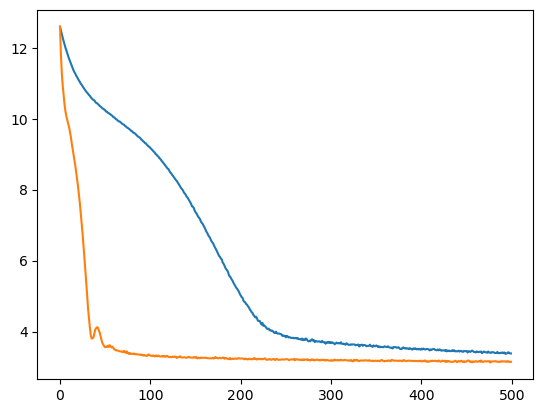

In [173]:
plt.plot(range(epochs), losses)
plt.plot(range(epochs), lossesList)

In [174]:
with torch.no_grad():
    y_val = model(cat_test, cont_test)
    loss = torch.sqrt(criterion(y_val, y_test))
    # loss = criterion(y_val, y_test)

In [175]:
loss

tensor(3.3755)

In [ ]:
for i in range(10):
    print(f"{i + 1}.) error: {(y_val[i] - y_test[i]).item():5.2f}")

1.) error:  1.10
2.) error: 15.74
3.) error: -3.70
4.) error:  1.60
5.) error:  0.46
6.) error:  1.31
7.) error:  1.33
8.) error:  4.17
9.) error: -0.99
10.) error:  0.83


In [232]:
cont_test

tensor([[-73.9528,  40.7834, -73.9560,  40.7822,   1.0000,   0.2935],
        [-73.9840,  40.7550, -73.8852,  40.7727,   1.0000,   8.5440],
        [-73.9495,  40.7849, -73.9342,  40.8017,   2.0000,   2.2643],
        ...,
        [-74.0047,  40.7381, -73.9959,  40.7412,   1.0000,   0.8233],
        [-73.9724,  40.7593, -73.9831,  40.7415,   1.0000,   2.1771],
        [-73.9425,  40.8409, -74.0099,  40.7181,   1.0000,  14.7883]])

In [ ]:
for i in range(10):
    print(f"{i + 1}.) x_cats: {cat_test[i, :]} \n x_conts: {cont_test[i, :]}")
    print(f"y_val: {y_val[i].item():.5} \n  y_test: {y_test[i].item():.5}")

1.) x_cats: tensor([17,  1,  3]) 
 x_conts: tensor([-73.9528,  40.7834, -73.9560,  40.7822,   1.0000,   0.2935])
y_val: 4.0045 
  y_test: 2.9
2.) x_cats: tensor([16,  1,  1]) 
 x_conts: tensor([-73.9840,  40.7550, -73.8852,  40.7727,   1.0000,   8.5440])
y_val: 21.441 
  y_test: 5.7
3.) x_cats: tensor([18,  1,  2]) 
 x_conts: tensor([-73.9495,  40.7849, -73.9342,  40.8017,   2.0000,   2.2643])
y_val: 4.0027 
  y_test: 7.7
4.) x_cats: tensor([23,  1,  2]) 
 x_conts: tensor([-73.9564,  40.7720, -73.9194,  40.8181,   1.0000,   5.9935])
y_val: 14.103 
  y_test: 12.5
5.) x_cats: tensor([22,  1,  0]) 
 x_conts: tensor([-74.0001,  40.7432, -73.9991,  40.7498,   1.0000,   0.7339])
y_val: 4.5645 
  y_test: 4.1
6.) x_cats: tensor([14,  1,  0]) 
 x_conts: tensor([-74.0073,  40.7163, -73.9990,  40.7200,   1.0000,   0.8153])
y_val: 6.6115 
  y_test: 5.3
7.) x_cats: tensor([5, 0, 4]) 
 x_conts: tensor([-73.9517,  40.8119, -73.9553,  40.8146,   1.0000,   0.4265])
y_val: 5.0274 
  y_test: 3.7
8.) x_ca

In [ ]:
torch.save(model, "models/TaxiModelFare_fullmodel.pt")
torch.save(model.state_dict(), "models/TaxiModelFare_wb.pt")

In [ ]:
torch.save(modelList, "models/TaxiModelListFare_fullmodel.pt")
torch.save(modelList.state_dict(), "models/TaxiModelListFare_wb.pt")

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd


def haversine_distance(df, lat1, long1, lat2, long2):
    r = 6371
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])
    delta_phi = np.radians(df[lat2] - df[lat1])
    delta_lambda = np.radians(df[long2] - df[long1])
    a = (
        np.sin(delta_phi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    )
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return r * c


class TabularModel(nn.Module):
    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        super().__init__()
        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni, nf in emb_szs])
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)
        layerlist = []
        n_emb = sum((nf for ni, nf in emb_szs))
        n_in = n_emb + n_cont
        for i in layers:
            layerlist.append(nn.Linear(n_in, i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
        layerlist.append(nn.Linear(layers[-1], out_sz))
        self.layers = nn.Sequential(*layerlist)

    def forward(self, x_cat, x_cont):
        embeddings = []
        for i, e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:, i]))
        x = torch.cat(embeddings, 1)
        x = self.emb_drop(x)
        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        return self.layers(x)

In [ ]:
emb_szs = [(24, 12), (2, 1), (7, 4)]
model2 = TabularModel(emb_szs, 6, 1, [200, 100], p=0.4)
model2.load_state_dict(torch.load("models/TaxiModelFare_wb.pt"))
model2.eval()  # be sure to run this step!

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=23, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=1, bias=True)
  )
)

In [192]:
df.head(1)

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM,Weekday
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4,am,Mon


In [ ]:
def test_data(mdl):  # pass in the name of the new model
    # INPUT NEW DATA
    plat = float(input("What is the pickup latitude?  "))
    plong = float(input("What is the pickup longitude? "))
    dlat = float(input("What is the dropoff latitude?  "))
    dlong = float(input("What is the dropoff longitude? "))
    psngr = int(input("How many passengers? "))
    dt = input("What is the pickup date and time?\nFormat as YYYY-MM-DD HH:MM:SS     ")

    # PREPROCESS THE DATA
    dfx_dict = {
        "pickup_latitude": plat,
        "pickup_longitude": plong,
        "dropoff_latitude": dlat,
        "dropoff_longitude": dlong,
        "passenger_count": psngr,
        "EDTdate": dt,
    }
    dfx = pd.DataFrame(dfx_dict, index=[0])
    dfx["dist_km"] = haversine_distance(
        dfx,
        "pickup_latitude",
        "pickup_longitude",
        "dropoff_latitude",
        "dropoff_longitude",
    )

    dfx["EDTdate"] = pd.to_datetime(dfx["EDTdate"])

    # We can skip the .astype(category) step since our fields are small,
    # and encode them right away
    dfx["Hour"] = dfx["EDTdate"].dt.hour
    dfx["AMorPM"] = np.where(dfx["Hour"] < 12, 0, 1)
    dfx["Weekday"] = dfx["EDTdate"].dt.strftime("%a")
    dfx["Weekday"] = (
        dfx["Weekday"]
        .replace(
            ["Fri", "Mon", "Sat", "Sun", "Thu", "Tue", "Wed"], [0, 1, 2, 3, 4, 5, 6]
        )
        .astype("int64")
    )

    print(dfx)

    # CREATE CAT AND CONT TENSORS
    cat_cols = ["Hour", "AMorPM", "Weekday"]
    cont_cols = [
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude",
        "passenger_count",
        "dist_km",
    ]
    xcats = np.stack([dfx[col].values for col in cat_cols], 1)
    xcats = torch.tensor(xcats, dtype=torch.int64)
    xconts = np.stack([dfx[col].values for col in cont_cols], 1)
    xconts = torch.tensor(xconts, dtype=torch.float)

    print(xcats)

    # PASS NEW DATA THROUGH THE MODEL WITHOUT PERFORMING A BACKPROP
    with torch.no_grad():
        z = mdl(xcats, xconts)
    print(f"\nThe predicted fare amount is ${z.item():.2f}")

In [202]:
z = test_data(model2)


The predicted fare amount is $4206.34


In [ ]:
model_load = torch.load("models/TaxiModelFare_fullmodel.pt")
model_load.eval()

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=23, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=1, bias=True)
  )
)

In [239]:
z = test_data(model_load)

   pickup_latitude  pickup_longitude  dropoff_latitude  dropoff_longitude  \
0             40.5             -73.9             40.52             -73.92   

   passenger_count             EDTdate   dist_km  Hour  AMorPM  Weekday  
0                2 2010-04-15 16:00:00  2.793667    16       1        4  
tensor([[16,  1,  4]])

The predicted fare amount is $16.21


In [ ]:
4209.93 - 4192.48

17.450000000000728

In [236]:
model.eval()
z = test_data(model)

   pickup_latitude  pickup_longitude  dropoff_latitude  dropoff_longitude  \
0            -73.9              40.5            -73.92              40.52   

   passenger_count             EDTdate   dist_km  Hour  AMorPM  Weekday  
0                2 2010-04-15 16:00:00  2.307728    16       1        4  
tensor([[16,  1,  4]])

The predicted fare amount is $15.96
